# 🚗 Too Random to Be Real: Catching Fabricated Odometer Readings with Digit Tests

The [Benford's Law notebook](../benfords-test/benfords-analysis.ipynb) tested whether purchase-card amounts follow Benford's first-digit distribution. The [Nigeria vs. Sweden notebook](../nigeria-sweden-elections/election-last-digits.ipynb) showed that rigged vote counts are given away by their last digits: too many of them end in 0.

This case is the mirror image. The fabricated data here have **too few** round numbers. Real people round when they write down an odometer reading; a random-number generator does not. The data come from a famous field experiment on honesty whose results turned out to be fabricated, and the paper was retracted in 2021.

Along the way, the notebook shows that Benford's Law cannot tell the genuine readings from the fabricated ones, and that a naive last-digit test points at the *wrong* half of the data. The test that works compares digit patterns **between** groups.

## ✨ Background

### The study

In 2012, Shu, Mazar, Gino, Ariely and Bazerman published a paper in *PNAS* arguing that people are more honest when they sign an honesty pledge at the **top** of a form than at the bottom. Study 3 was a field experiment with a US car insurance company. Customers reported the current odometer reading of each car on their policy. A lower mileage means a lower premium, so customers have an incentive to under-report. The paper reported that customers who signed at the top reported driving about 2,400 more miles (roughly 10% more) than those who signed at the bottom.

### The fraud

In August 2021, the blog [Data Colada](https://datacolada.org/98) (Uri Simonsohn, Joe Simmons and Leif Nelson, working with a team of anonymous researchers) showed that the Study 3 data were fabricated. The main evidence:

1. **Miles driven are uniformly distributed** between 0 and 50,000, with nothing above 50,000. Real driving distances do not look like that.
2. **The updated odometer readings show no rounding**, unlike readings written down by real people.
3. **Half of the baseline readings are near-copies of the other half**, shifted up by a small random amount and stored in a different font (Calibri vs. Cambria).

*PNAS* retracted the paper on September 13, 2021. Data Colada did not use Benford's Law; this notebook reproduces their evidence and then asks what Benford's Law and last-digit tests would have shown.

### Data

The original data file was posted by the authors on the Open Science Framework (OSF) in project [osf.io/3javq](https://osf.io/3javq/). OSF lists no license for it, so it is not stored in this repository; the notebook downloads it on first run. Data Colada also posted a copy, with their analysis code, at [ResearchBox #336](https://researchbox.org/336) under a CC BY 4.0 license.

Each row is one insurance policy, with up to four cars. For each car the file has two readings:

- **Previous:** the odometer reading the customer had reported to the insurer earlier (the *baseline*).
- **Update:** the reading the customer reported on the form in the study.

The difference between them is the number of miles driven. The analysis focuses on car 1, which every policy has.

## Import packages

In [1]:
from pathlib import Path
import urllib.request

import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import xlrd
from scipy import stats

pio.templates['sans_serif'] = go.layout.Template(dict(layout=go.Layout(
    font_family='Helvetica, Inter, Arial, sans-serif')))
pio.templates.default = 'simple_white+sans_serif'

GROUP_COLORS = {
    'Baseline (customer-reported)': '#00798C',
    'Update (study form)': '#D1495B',
    'Calibri': '#00798C',
    'Cambria': '#D1495B',
}
EXPECTED_COLOR = '#9E9E9E'

---

## 📥 Download and load the data

The file is an Excel 97–2003 workbook (`.xls`), so pandas needs the `xlrd` package to read it.

In [2]:
DATA_URL = 'https://osf.io/download/wph5v/'
DATA_FILE = Path('DrivingdataAll.xls')

if not DATA_FILE.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df_raw = pd.read_excel(DATA_FILE, sheet_name='Data', engine='xlrd')
print(df_raw.shape)
df_raw.head(3)

(13488, 18)


,OMR Version,Policy # (masked),Odom Reading 1 (Previous),Odom Reading 1 (Update),Odom Reading 2 (Previous),Odom Reading 2 (Update),Odom Reading 3 (Previous),Odom Reading 3 (Update),Odom Reading 4 (Previous),Odom Reading 4 (Update),Odom Reading All (Previous),Odom Reading All (Update),Diff All,Count1,Count2,Count3,Count4,#Cars in Policy
0,Sign Top,1,896,39198,NaN,NaN,NaN,NaN,NaN,NaN,896.0,39198.0,38302.0,1,0,0,0,1
1,Sign Bottom,2,21396,63511,32659.0,47605.0,NaN,NaN,NaN,NaN,27027.5,55558.0,28530.5,1,1,0,0,2
2,Sign Bottom,3,21340,37460,44998.0,59002.0,NaN,NaN,NaN,NaN,33169.0,48231.0,15062.0,1,1,0,0,2


In [3]:
df = df_raw.rename(columns={
    'OMR Version': 'condition',
    'Policy # (masked)': 'policy',
    'Odom Reading 1 (Previous)': 'baseline',
    'Odom Reading 1 (Update)': 'update',
    '#Cars in Policy': 'cars',
})[['policy', 'condition', 'cars', 'baseline', 'update']]

df[['baseline', 'update']] = df[['baseline', 'update']].astype('int64')
df['miles_driven'] = df['update'] - df['baseline']

df.describe().round(0)

,policy,cars,baseline,update,miles_driven
count,13488.0,13488.0,13488.0,13488.0,13488.0
mean,6744.0,2.0,67356.0,92285.0,24929.0
std,3894.0,1.0,56761.0,58578.0,14422.0
min,1.0,1.0,0.0,42.0,8.0
25%,3373.0,1.0,25274.0,50088.0,12278.0
50%,6744.0,1.0,56342.0,82382.0,25042.0
75%,10116.0,2.0,96259.0,123314.0,37388.0
max,13488.0,4.0,983155.0,1010893.0,49997.0


### Recover the cell fonts

pandas reads cell values, not formatting. `xlrd` can also read each cell's formatting when the workbook is opened with `formatting_info=True`. The function below looks up the font of every car 1 baseline reading.

In [4]:
book = xlrd.open_workbook(DATA_FILE, formatting_info=True)
sheet = book.sheet_by_name('Data')
baseline_col = df_raw.columns.get_loc('Odom Reading 1 (Previous)')


def cell_font(row, col):
    xf = book.xf_list[sheet.cell_xf_index(row, col)]
    return book.font_list[xf.font_index].name


# Row 0 of the sheet is the header, so data rows start at 1
df['baseline_font'] = [cell_font(row, baseline_col) for row in range(1, sheet.nrows)]
df['baseline_font'].value_counts()

baseline_font
Cambria    6744
Calibri    6744
Name: count, dtype: int64

Exactly half of the baseline readings are in Calibri and half in Cambria. Every other column in the sheet uses a single font. Hold that thought; it comes back in Step 4.

---

## 1️⃣ Step 1: How far did customers drive?

Real driving distances should bunch around typical values, with a long tail of people who drive a lot. The histogram below shows what the data say.

In [5]:
ks = stats.kstest(df['miles_driven'], 'uniform', args=(0, 50_000))
print(f"Miles driven: min {df['miles_driven'].min():,}, max {df['miles_driven'].max():,}")
print(f"Policies with more than 50,000 miles: {(df['miles_driven'] > 50_000).sum()}")
print(f"Kolmogorov-Smirnov test against a uniform distribution from 0 to 50,000: D = {ks.statistic:.4f}, p = {ks.pvalue:.2f}")

Miles driven: min 8, max 49,997
Policies with more than 50,000 miles: 0
Kolmogorov-Smirnov test against a uniform distribution from 0 to 50,000: D = 0.0053, p = 0.83


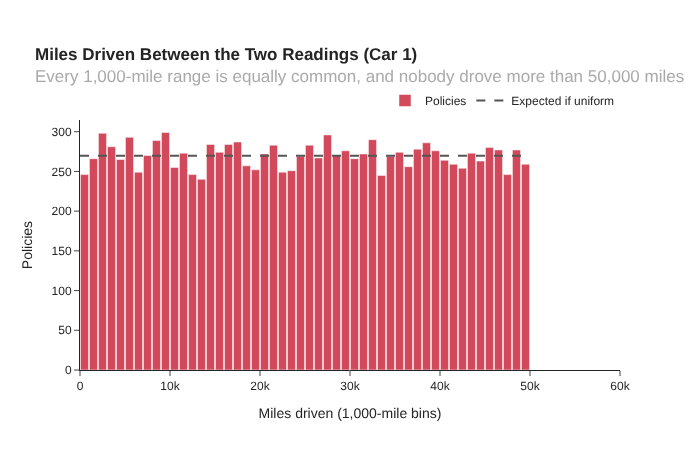

In [6]:
bin_edges = np.arange(0, 51_000, 1_000)
counts, _ = np.histogram(df['miles_driven'], bins=bin_edges)

fig = go.Figure()
fig.add_trace(go.Bar(
    x=bin_edges[:-1] + 500, y=counts, width=900, name='Policies', marker_color='#D1495B',
))
fig.add_trace(go.Scatter(
    x=[0, 50_000], y=[len(df) / 50] * 2, mode='lines', name='Expected if uniform',
    line=dict(color='#555555', dash='dash', width=2),
))
fig.update_layout(
    height=450,
    title='<b>Miles Driven Between the Two Readings (Car 1)</b><br>'
          '<span style="color: #aaa">Every 1,000-mile range is equally common, and nobody drove more than 50,000 miles</span>',
    xaxis_title_text='Miles driven (1,000-mile bins)',
    xaxis_range=[0, 60_000],
    yaxis_title_text='Policies',
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='right', x=1),
    margin=dict(t=120),
)
fig.show()

The Kolmogorov–Smirnov test cannot distinguish miles driven from a perfectly uniform distribution between 0 and 50,000 (p ≈ 0.83, matching the 0.84 Data Colada report). That is what Excel's `RANDBETWEEN(0, 50000)` would produce. It is not what real driving looks like.

---

## 2️⃣ Step 2: Would Benford's Law have caught it?

The functions below reproduce the Benford tests and Nigrini's MAD thresholds from the Benford notebook, then apply them to three columns: the baseline readings, the updated readings and miles driven.

In [7]:
BENFORD_FIRST = pd.Series(np.log10(1 + 1 / np.arange(1, 10)), index=range(1, 10))
BENFORD_SECOND = pd.Series(
    [sum(np.log10(1 + 1 / (10 * d1 + d2)) for d1 in range(1, 10)) for d2 in range(10)],
    index=range(10),
)
BENFORD_FIRST_TWO = pd.Series(np.log10(1 + 1 / np.arange(10, 100)), index=range(10, 100))


def digit_proportions(values, position):
    """Proportions of the first digit ('first'), second digit ('second') or first two digits ('first_two')."""
    values = values[values >= 10].astype('int64').astype(str)
    if position == 'first':
        digits, index = values.str[0], range(1, 10)
    elif position == 'second':
        digits, index = values.str[1], range(10)
    else:
        digits, index = values.str[:2], range(10, 100)
    return digits.astype(int).value_counts(normalize=True).reindex(index, fill_value=0)


def mad(actual, expected):
    return (actual - expected).abs().mean()


def conformity(mad, cutoffs):
    labels = ['Close Conformity', 'Acceptable Conformity', 'Marginal Conformity']
    for cutoff, label in zip(cutoffs, labels):
        if mad < cutoff:
            return label
    return 'Nonconformity'


NIGRINI_CUTOFFS = {
    'first': (0.006, 0.012, 0.015),
    'second': (0.008, 0.010, 0.012),
    'first_two': (0.0012, 0.0018, 0.0022),
}
EXPECTED = {'first': BENFORD_FIRST, 'second': BENFORD_SECOND, 'first_two': BENFORD_FIRST_TWO}


def benford_summary(values):
    row = {}
    for position, expected in EXPECTED.items():
        value = mad(digit_proportions(values, position), expected)
        row[f'{position} MAD'] = round(value, 4)
        row[f'{position} verdict'] = conformity(value, NIGRINI_CUTOFFS[position])
    return row

In [8]:
pd.DataFrame({
    'Baseline (customer-reported)': benford_summary(df['baseline']),
    'Update (study form)': benford_summary(df['update']),
    'Miles driven': benford_summary(df['miles_driven']),
}).T

,first MAD,first verdict,second MAD,second verdict,first_two MAD,first_two verdict
Baseline (customer-reported),0.0216,Nonconformity,0.0075,Close Conformity,0.0026,Nonconformity
Update (study form),0.0339,Nonconformity,0.0065,Close Conformity,0.0037,Nonconformity
Miles driven,0.0599,Nonconformity,0.0107,Marginal Conformity,0.006,Nonconformity


Every column fails the first-digit and first-two-digit tests, and every column passes the second-digit test, so neither test separates the columns. Step 4 shows that half of the baseline readings are genuine, and that half fails the first-digit test too. Odometer readings are not a Benford-type variable: most cars have between roughly 20,000 and 150,000 miles on them, so the leading digit mostly reflects the age of the fleet. Miles driven fails worst, but only because a uniform distribution between 0 and 50,000 overloads leading digits 1 to 4, which is something the histogram in Step 1 already showed directly.

A test that also rejects the genuine data cannot be used to flag the fabricated data. Benford's Law is the wrong reference distribution here.

---

## 3️⃣ Step 3: Look at the last digits

When people read an odometer and write the number down, they often round: 45,000 instead of 44,968. In genuine customer-reported readings, that rounding should show up as an excess of readings ending in 0, 00 and 000. A random-number generator has no reason to round.

In [9]:
def format_p(p):
    return f'{p:.2g}' if p > 1e-300 else '< 1e-300'


def p_text(p):
    return f'p = {p:.2g}' if p > 1e-300 else 'p < 1e-300'


def rounding_summary(values):
    values = values.astype('int64')
    last_digits = (values % 10).value_counts().reindex(range(10), fill_value=0)
    chi2, p_value = stats.chisquare(last_digits)
    return {
        'n': len(values),
        'ends in 0': (values % 10 == 0).mean(),
        'ends in 00': (values % 100 == 0).mean(),
        'ends in 000': (values % 1000 == 0).mean(),
        'chi-square vs uniform': round(chi2, 1),
        'p-value vs uniform': p_value,
    }


pd.DataFrame({
    'Baseline (customer-reported)': rounding_summary(df['baseline']),
    'Update (study form)': rounding_summary(df['update']),
}).T.style.format({
    'n': '{:,.0f}', 'ends in 0': '{:.1%}', 'ends in 00': '{:.1%}', 'ends in 000': '{:.1%}',
    'chi-square vs uniform': '{:,.1f}', 'p-value vs uniform': format_p,
})

,n,ends in 0,ends in 00,ends in 000,chi-square vs uniform,p-value vs uniform
Baseline (customer-reported),"13,488",23.9%,14.6%,10.4%,"2,923.2",< 1e-300
Update (study form),"13,488",10.4%,1.1%,0.1%,4.8,0.85


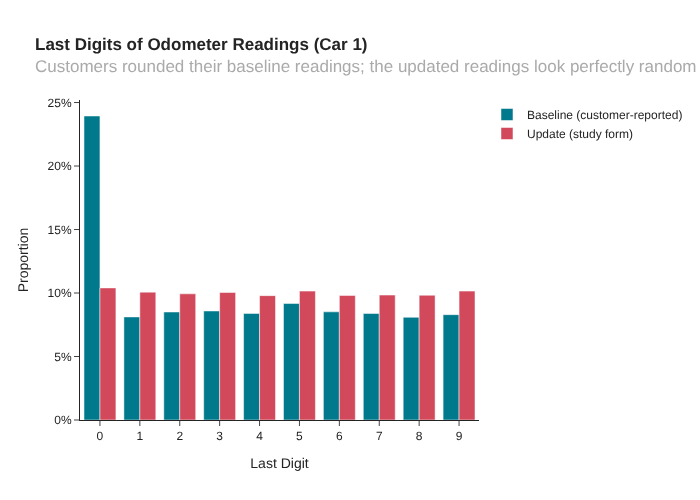

In [10]:
def last_digit_shares(values, label):
    shares = (values.astype('int64') % 10).value_counts(normalize=True).reindex(range(10), fill_value=0)
    return shares.rename('proportion').rename_axis('digit').reset_index().assign(Group=label)


last_digit_df = pd.concat([
    last_digit_shares(df['baseline'], 'Baseline (customer-reported)'),
    last_digit_shares(df['update'], 'Update (study form)'),
])

fig = px.bar(
    last_digit_df,
    x='digit',
    y='proportion',
    color='Group',
    barmode='group',
    color_discrete_map=GROUP_COLORS,
    height=500,
    title='<b>Last Digits of Odometer Readings (Car 1)</b><br>'
          '<span style="color: #aaa">Customers rounded their baseline readings; the updated readings look perfectly random</span>',
    labels={'digit': 'Last Digit'},
)
fig.add_hline(y=0.1, line_dash='dash', line_color='#555555')
fig.update_layout(yaxis_title_text='Proportion', yaxis_tickformat=',.0%', legend_title=None)
fig.update_xaxes(dtick=1)
fig.show()

### The twist: the uniform test points the wrong way

In the [Nigeria vs. Sweden notebook](../nigeria-sweden-elections/election-last-digits.ipynb), the fraudulent counts were the ones that *failed* a test of uniform last digits. Here it is the other way around:

- The **baseline** readings, which carry the signature of human rounding, fail spectacularly.
- The **updated** readings pass, with a p-value near 0.85: their last digits are as even as a random-number generator's.

A test against a fixed reference distribution, whether Benford or uniform, only works if you know how genuine data should look. Odometer readings written down by people are *supposed* to have extra zeros. The more reliable approach is to compare the suspect data with genuine data of the same kind. A chi-square test of homogeneity asks whether two groups share the same last-digit distribution, without assuming what that distribution is.

In [11]:
def homogeneity_test(values_a, values_b):
    table = pd.DataFrame({
        'a': (values_a.astype('int64') % 10).value_counts().reindex(range(10), fill_value=0),
        'b': (values_b.astype('int64') % 10).value_counts().reindex(range(10), fill_value=0),
    })
    result = stats.chi2_contingency(table)
    return result.statistic, result.pvalue


chi2, p_value = homogeneity_test(df['baseline'], df['update'])
print(f'Baseline vs. update last digits: chi-square = {chi2:,.1f} (9 df), {p_text(p_value)}')

Baseline vs. update last digits: chi-square = 875.1 (9 df), p = 1.4e-182


---

## 4️⃣ Step 4: The font clue

Step 3 compared the baseline readings with the updated readings. But Data Colada found that the baseline column is itself a mix of two groups, stored in two fonts. If one group is genuine and the other was manufactured, their digits should differ.

In [12]:
calibri = df.loc[df['baseline_font'] == 'Calibri', 'baseline']
cambria = df.loc[df['baseline_font'] == 'Cambria', 'baseline']

pd.DataFrame({
    'Calibri': rounding_summary(calibri),
    'Cambria': rounding_summary(cambria),
}).T.style.format({
    'n': '{:,.0f}', 'ends in 0': '{:.1%}', 'ends in 00': '{:.1%}', 'ends in 000': '{:.1%}',
    'chi-square vs uniform': '{:,.1f}', 'p-value vs uniform': format_p,
})

,n,ends in 0,ends in 00,ends in 000,chi-square vs uniform,p-value vs uniform
Calibri,"6,744",37.9%,27.9%,20.6%,"5,846.5",< 1e-300
Cambria,"6,744",10.0%,1.2%,0.1%,13.8,0.13


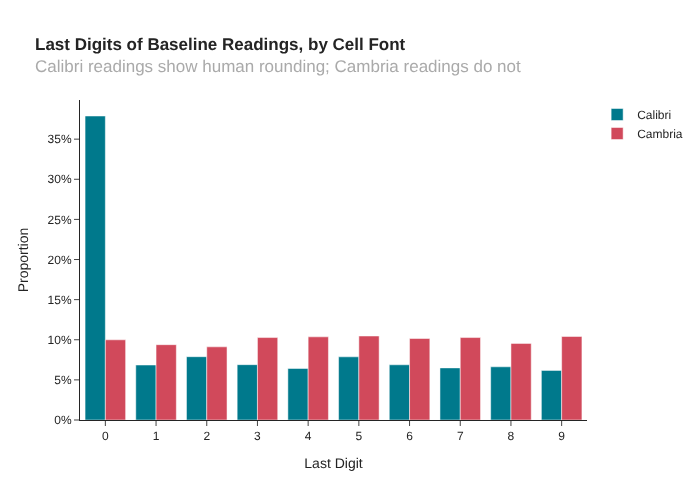

Calibri vs. Cambria last digits: chi-square = 1,468.8 (9 df), p < 1e-300


In [13]:
font_df = pd.concat([
    last_digit_shares(calibri, 'Calibri'),
    last_digit_shares(cambria, 'Cambria'),
])

fig = px.bar(
    font_df,
    x='digit',
    y='proportion',
    color='Group',
    barmode='group',
    color_discrete_map=GROUP_COLORS,
    height=500,
    title='<b>Last Digits of Baseline Readings, by Cell Font</b><br>'
          '<span style="color: #aaa">Calibri readings show human rounding; Cambria readings do not</span>',
    labels={'digit': 'Last Digit'},
)
fig.add_hline(y=0.1, line_dash='dash', line_color='#555555')
fig.update_layout(yaxis_title_text='Proportion', yaxis_tickformat=',.0%', legend_title=None)
fig.update_xaxes(dtick=1)
fig.show()

chi2, p_value = homogeneity_test(calibri, cambria)
print(f'Calibri vs. Cambria last digits: chi-square = {chi2:,.1f} (9 df), {p_text(p_value)}')

The Calibri readings round like the customer-reported data they are supposed to be. The Cambria readings have last digits that look like a random-number generator's.

### Twins

Data Colada also found that each Cambria reading looks like a Calibri reading plus a small random amount. A simple check: sort each group, pair the smallest Calibri reading with the smallest Cambria reading, the second smallest with the second smallest, and so on, then look at the differences.

In [14]:
twin_gap = pd.Series(np.sort(cambria.values) - np.sort(calibri.values), name='gap')
print(f"Gap between rank-paired Cambria and Calibri readings: min {twin_gap.min():,}, max {twin_gap.max():,}, median {twin_gap.median():,.0f}")
print(f"Share of gaps between 0 and 1,000 miles: {twin_gap.between(0, 1000).mean():.1%}")

Gap between rank-paired Cambria and Calibri readings: min 6, max 986, median 505
Share of gaps between 0 and 1,000 miles: 100.0%


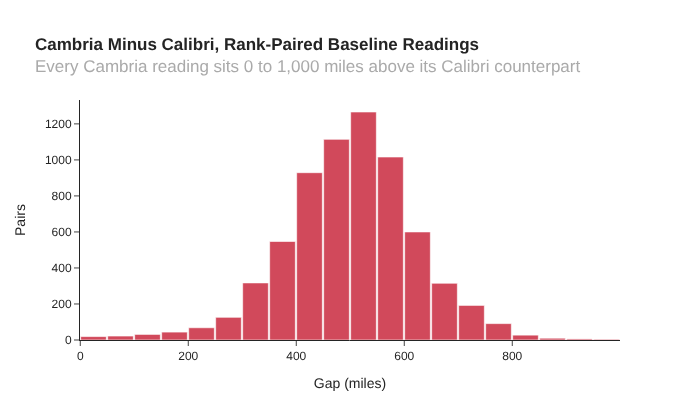

In [15]:
fig = px.histogram(
    twin_gap,
    nbins=40,
    height=420,
    color_discrete_sequence=['#D1495B'],
    title='<b>Cambria Minus Calibri, Rank-Paired Baseline Readings</b><br>'
          '<span style="color: #aaa">Every Cambria reading sits 0 to 1,000 miles above its Calibri counterpart</span>',
    labels={'value': 'Gap (miles)'},
)
fig.update_layout(yaxis_title_text='Pairs', showlegend=False, bargap=0.05)
fig.show()

Across 6,744 pairs spanning odometer readings from zero to almost a million miles, every Cambria reading sits between 0 and 1,000 miles above its rank-paired Calibri reading. Two independent sets of customer-reported readings would not line up like that: some gaps would be negative, and gaps in the sparse upper tail would run to thousands of miles.

The pattern fits Data Colada's explanation that the Cambria rows were made by copying the Calibri rows and adding a random number between 0 and 1,000. If every Cambria reading is its twin plus 0 to 1,000 miles, the k-th smallest Cambria reading must lie 0 to 1,000 miles above the k-th smallest Calibri reading. (The gaps cluster around 500 rather than looking uniform because sorting scrambles the original twin pairs.)

### And Benford's Law?

In [16]:
pd.DataFrame({
    'Calibri': benford_summary(calibri),
    'Cambria': benford_summary(cambria),
}).T

,first MAD,first verdict,second MAD,second verdict,first_two MAD,first_two verdict
Calibri,0.0208,Nonconformity,0.0091,Acceptable Conformity,0.0025,Nonconformity
Cambria,0.0225,Nonconformity,0.0063,Close Conformity,0.0028,Nonconformity


Benford's Law sees almost no difference between the two fonts. Adding a few hundred miles to a reading of 40,000 leaves its leading digits unchanged, so copied rows inherit the leading-digit pattern of the rows they were copied from. Last digits, on the other hand, are exactly where the random noise was added.

---

## 📌 Key Findings

1. **The miles-driven data are too smooth to be real.** Miles driven are indistinguishable from a uniform distribution between 0 and 50,000 (Kolmogorov–Smirnov p = 0.83), with not a single policy above 50,000 miles.
2. **Benford's Law cannot see the fabrication.** All three columns fail the first-digit and first-two-digit tests and pass the second-digit test. Split by font, the genuine Calibri and copied Cambria baseline readings get almost identical first-digit MADs (0.021 and 0.023). Odometer readings do not span the orders of magnitude Benford's Law needs, and copying a reading while adding a few hundred miles leaves its leading digits intact.
3. **The last digits give it away, but in the opposite direction from election fraud.** 37.9% of Calibri baseline readings end in 0 and 20.6% end in 000, the signature of people rounding. Only 10.0% of Cambria readings and 10.4% of updated readings end in 0, and just 0.1% end in 000, exactly what a random-number generator produces.
4. **A fixed reference distribution can mislead.** Tested against uniform last digits, the baseline readings fail and the updated readings pass (p = 0.85), which points at the wrong data. Comparing groups directly with a chi-square test of homogeneity separates Calibri from Cambria (chi-square = 1,469, 9 df) and baseline from update (chi-square = 875).
5. **Half of the baseline readings are copies.** Rank-paired, every Cambria reading sits 0 to 1,000 miles above a Calibri reading, consistent with rows that were duplicated and nudged by a random amount.

## Case Study Potential

**Verdict: Strong.** The story is famous and well documented (a retracted paper about honesty, with fabricated data), the data are free to download, and the forensic steps are simple enough for students to reproduce in an afternoon. The case pairs naturally with the Benford and Nigeria vs. Sweden notebooks. Together they show that the same family of digit tests can catch fraud in opposite directions, and that the test has to match how genuine data are generated.

- **Strengths:** a documented fraud with a public forensic write-up, a single 7 MB file, an unusual data-wrangling lesson (reading cell fonts with `xlrd`), and a counterintuitive result: the genuine data fail the uniformity test.
- **Weaknesses:** the file has no license on OSF, so the course should link to it or use Data Colada's CC BY 4.0 copy rather than redistribute the OSF file. The font clue is specific to this file and will not generalize to other fraud cases.

**Suggested framing:** *You are a data analyst at a journal. A reader has flagged a highly cited field experiment. Using only the posted data file, decide whether the data are trustworthy, and explain your evidence to an editor who has never heard of Benford's Law.*

**Discussion questions:**

1. Why do genuine odometer readings fail a test of uniform last digits? What does that tell you about using a fixed reference distribution?
2. Benford's Law flags all three columns in Step 2. Why is that not evidence of fraud?
3. Copying rows and adding a random number between 0 and 1,000 changes the last digits but barely changes the first digits. Which kinds of fabrication would Benford's Law be good at catching, and which would it miss?
4. What evidence beyond digit tests would you want before concluding the data were fabricated?
5. Data Colada's case rested on several independent anomalies. Why is a combination of weak signals more convincing than one strong one?

## References

- Shu, L. L., Mazar, N., Gino, F., Ariely, D., & Bazerman, M. H. (2012). Signing at the beginning makes ethics salient and decreases dishonest self-reports in comparison to signing at the end. *PNAS*, 109(38), 15197–15200. Retracted September 13, 2021. [doi:10.1073/pnas.1209746109](https://doi.org/10.1073/pnas.1209746109)
- Simonsohn, U., Simmons, J., & Nelson, L. (2021). [98] Evidence of Fraud in an Influential Field Experiment About Dishonesty. *Data Colada*. [datacolada.org/98](https://datacolada.org/98)
- Original data: OSF project [osf.io/3javq](https://osf.io/3javq/), file `DrivingdataAll (1).xls`.
- Data Colada's copy of the data and code: [ResearchBox #336](https://researchbox.org/336) (CC BY 4.0).